# Лекция 1

## Метод купных частиц  
## Часть 7

<a id = "s_sec25"></a>
### 25. Метод частиц в ячейках.

&nbsp; Рассмотрим в этом разделе метод частиц в ячейках (particle-in-cell) для однокомпонентной среды. Метод частиц в ячейках был предложен в лаборатории Лос-Аламос (США) Френсисом Х. Харлоу в 1955 году. Данный метод зарекомендовал себя в большей степени для решения задач физики плазмы, однако ряд численных подходов на основе метода частиц в ячейках также плодотворно используется для расчетов динамики жидкостей и газов. 

&nbsp; В методе частиц в ячейках используется дискретная модель сплошной среды, причем занятое жидкостью пространство разбивается сеткой фиксированных ячеек. Внутри этих ячеек сплошная среда представляется частицами, каждая из которох несет фиксированную массу жидкости. Таким образом, имеем лагранжеву систему координат (частиц), наложенную на неподвижную эйлерову сетку.

&nbsp; Для простоты предположим, что граница исследуемой области $\tau$ фискирована и поток через неё равен нулю. Пусть вещество характеризуется одним уравнением состояния, которое связывает величины плотности $\rho$, давления $p$ и удельной внутренней энергии $\epsilon$.

&nbsp; В соответствии с трактовкой Лагранжа, скорость расчетной точки определяется из соотношения

\begin{equation}
\dot x = \frac{dx}{dt} = W(x,t)
\label{eq:lag_velocity}
\end{equation}

где $x$ и $W$ рассматриваются в одномерном случае как скаляры, а в многомерном - как векторы. 

&nbsp; Интегрируя уравение $\eqref{eq:lag_velocity}$ получим $x = x(x_0,t)$ - положение любой данной точки жидкости как функцию времени и её начального положения $x_0$. Распределение плотности $\rho(x,t)$ во времени $t$ должно удовлетворять закону сохранения массы, который можно записать в интегральной форме:

\begin{equation}
\int_{\tau} \rho (x,t) d \tau = \int_{\tau_0} \rho_0 (x_0) d \tau_0
\label{eq:cons_mass}
\end{equation}

где $\tau$ -фиксированная расчетная область (объем) в жидкости, $\tau_0$ - начальное положение этой области, $\rho_0$ - начальное распределение плотностей, а $d \tau$ и $d \tau_0$ - соответствующие элементы указанных объемных областей. 

&nbsp; В дифференциальной форме закон сохранения массы имеет вид:

\begin{equation}
\rho = \rho_0 \frac{d \tau_0}{d \tau} = \rho_0 \cdot J \left( \frac{x_0}{x} \right)
\label{eq:cons_mass_diff}
\end{equation}

здесь $J$ - якобиан в многомерном случае.

&nbsp; Дадим определение массы частицы. Предположим, что начальное распределение плотности $\rho_0$ представлено дельта-функциями, т.е. функциями, отличающимися от нуля только в конечном числе точек $x_{0K}$ и обращающимися в бесконечность в каждой из этих точек таким образом, что объемный интеграл от плотности в любой достаточно малой окрестности этих особых точек является постоянной характеристикой точки. Эту константу и назовем массой частицы, связанной с рассматриваемой точкой. 

&nbsp; Массы выбираются так, чтобы выполнялся закон сохранения, записанный в дискретной форме:

\begin{equation}
M = \int_{\tau} \rho (x,t) d \tau = \int_{\tau_0} \rho_0 (x_0) d \tau_0 = \sum_{K=1}^{n} \int_{\tau_K} \rho_0 (x_0) d \tau_0 = \sum_{K=1}^{n} m_K
\label{eq:cons_mass_discr}
\end{equation}

здесь рассматриваемая область $\tau$ разбивается на $n$ подобластей $\tau_K$ так, что каждая подобласть содержит только одну точку, в которой $\rho_0$ отличается от нуля. Для любой произвольной области $\tau$ получим:

\begin{equation}
\int_{\tau} \rho (x,t) d \tau = \int_{\tau_0} \rho_0 (x_0) d \tau_0 = \sum_{j}^{n} m_j
\label{eq:cons_mass_discr2}
\end{equation}

где сумма берется по тем частицам, которые находятся в области $\tau$ в момент времени $t$. В частности, эта область может быть свободна от частиц. В таком случае соответствующий интеграл равен нулю, однако это не нарушает закона сохранения в целом. 

&nbsp; Установив характеристики функции плотности и определив массу частицы, построим теперь с помощью законов сохранения импульса и энергии вычислительный процесс метода.

&nbsp; Предположим, что область $\tau$ покрыта эйлеровой расчетной сеткой, которая позволяет получать простые выражения для разностных представлений в любой ячейке $С$ такиих функций как градиент, дивергенция и нормальная производная. Соответствующее значение плотности находим из интеграла в левой части:

\begin{equation}
\int_{\tau_C} \rho d \tau = \rho_C \tau_C
\label{eq:approx_rho}
\end{equation}

откуда следует, что

\begin{equation}
\rho_С = \frac{1}{\tau_c} \sum_C m_j
\label{eq:rho_c}
\end{equation}

расчетный цикл (шаг по времени $\Delta t$) при переходе от временного слоя $t$ к следующему $t+\Delta t$ в методах частиц расщепляется по физическим процессам для каждой расчетной ячейки на три этапа:

- На первом, эйлеровом этапе рассматривается изменение параметров жидкости за счет сил давления в элементарном объеме, фиксированном в жидкости (лагранжевой ячейке) и совпадающим в момент времени $t^n$ с эйлеровой ячейкой - при этом происходит, естественно, изменение границ лагранжевой ячейки.

- На втором, лагранжевом этапе, проводится регуляризация расчетной сетги - лагранжев объем "возвращается" в первоначальное положение и моделируется движение потока частиц через границы эйлеровых ячеек, учиывающее обмен массой между ячейками при их перестройке (в результате чего происходит перераспределение частиц по эйлеровой сетке за период $\Delta t$); 

- На третьем заключительном этапе происходит соответствующее перераспределение массы, импульса и энергии по пространству на основе законов сохранения (здесь определяется за $\Delta t$ изменение параметров поля течения  в элементарной ячейке, полученной возвращением лагранжевого объема в прежнее положение).

&nbsp; По существу, расчет ведется в локальной лагранжевой системе координат, с последующим пересчетм (интерполяцией) на эйлерову сетку.

&nbsp; Первоначальная структура расченой сетки остается здесь фиксированной в том смысле, что она вновь "появляется" в конце каждого расчетного цикла инегрирования. Следовательно, этот метод не испытывает сложностей, присущих чисто лагранжевым методикам (искажение лагранжевых ячеек). 

&nbsp; В дальнейшем мы будем обозначать через $L_i$ лагранжеву ячейку, фиксированную в жидкости $E_i$ - эйлерову ячейку, фиксированную в пространстве. 
Рассмотрим каждый этап в отдельности. 

&nbsp; 
##### I. Эйлеров этап. 
&nbsp; Выпишем законы сохранения импульса и энергии для области $\tau$:

\begin{equation}
\frac{d}{dt}\int_{\tau} \rho \vec W d\tau = - \int_{s_{\tau}} p \vec n \cdot ds 
\label{eq:momentum_cons_int}
\end{equation}

\begin{equation}
\frac{d}{dt}\int_{\tau} \rho E d\tau = \frac{d}{dt} \int_{\tau} \rho \left(\epsilon +\frac{1}{2} W^2\right) d\tau =  \int_{s_{\tau}} \left( p \vec W \right)_n ds
\label{eq:energy_cons_int}
\end{equation}

где $E$ - удельная полная энергия, $\epsilon$ - удельная внутренняя энергия, $ds$ - элемент поверхности, $(p \vec W)_n$ - нормальная компонента $p \vec W$, $\vec n(x,t)$ - единичная внешняя нормаль к поверхности, $s_\tau$ - поверхность, ограничивающая объем $\tau$. 

&nbsp; Запишем теперь систему $\eqref{eq:momentum_cons_int}\eqref{eq:energy_cons_int}$ для каждой лагранжевой ячейки сетки:

\begin{equation}
\frac{d}{dt}\int_{L_i} \rho \vec W d\tau = - \int_{s_{L_i}} p \vec n \cdot ds 
\label{eq:momentum_cons_int_cell}
\end{equation}

\begin{equation}
\frac{d}{dt}\int_{\tau} \rho \epsilon d\tau + \frac{d}{dt}\int_{\tau} \frac{1}{2} \rho W^2 d\tau =  \int_{s_{L_i}} \left( p \vec W \right)_n ds
\label{eq:energy_cons_int_cell}
\end{equation}


&nbsp; Заметим, что объемные ячейки $L_i$ и их поверхности $s_{L_i}$ здесь являются функциями времени, хотя в начале каждого расчетного цикла они совпадают с фиксированной эйлеровой сеткой. 

&nbsp; Интегрируя $\eqref{eq:momentum_cons_int_cell}\eqref{eq:energy_cons_int_cell}$ от $t$ до $t+\Delta t$, получим:

\begin{equation}
\int_{L_i(t+\Delta t} \rho \vec W d\tau = \int_{L_i(t} \rho \vec W d\tau - \int^{t+\Delta t}_{t} \int_{s_{L_i}(t)} p \vec n \cdot ds dt
\label{eq:momentum_cons_int_tint}
\end{equation}

\begin{equation}
\int_{L_{i}(t+\Delta t)} \rho \epsilon d\tau = - \frac{1}{2} \left[ \int_{L_{i}(t+\Delta t)} \rho W^2 d\tau -  \int_{L_{i}(t)} \rho W^2 d\tau \right] + \\ + \int_{L_{i}(t)} \rho \epsilon d\tau - \int^{t+\Delta t}_{t} \int_{s_{L_i}} \left( p \vec W \right)_n ds dt
\label{eq:energy_cons_int_tint}
\end{equation}

&nbsp; В выборе конкретных формул для приближенного вычисления интегралов $\eqref{eq:momentum_cons_int_tint},\eqref{eq:energy_cons_int_tint}$ имеется определенная свобода. В методе частиц обычно это делается следующим образом:

- а) временные интегрвалы равны произведению подынтегральных выражений в начальныйы момент $t$ и приращения времени $\Delta t$:

\begin{equation}
\int^{t+\Delta t}_{t} \int_{s_{L_i}(t)} p \vec n \cdot ds dt = \Delta t \int_{s_{L_i}(t)} p \vec n \cdot ds
\end{equation}

\begin{equation}
\int^{t+\Delta t}_{t} \int_{s_{L_i}(t)} p \vec n \cdot ds dt = \Delta t \int_{s_{L_i}(t)} p \vec n \cdot ds
\end{equation}

- б) объемные интегралы, входящие в $\eqref{}$ имеют вид

где $f$ - функция от x, а $t^*$ может быть равно либо $t$ либо $t+\Delta t$.
Тогда

но $L_i$ - лагранжева ячейка, следовательно, 

&nbsp; Здесь суммирование проводится по всем "массовым" точкам (частицам), находящимся внутри ячейки $L_i$. 

&nbsp; Пусть $t=n \cdot \Delta t$. Введем следующие обозначения для $f$:

&nbsp; Заменяя уравнения $\eqref{}$ (или $\eqref{}$) разностными соотношениями, получим

&nbsp; Величины подынтегральных выражений в поверхностных интегралах выбираются следующим образом: при суммировании уравнений $\eqref{}$ пов всем ячейкам $L_i$ в области $\tau$ сумма частных интегралов должна определять общий интеграл по ограничивающей поверхности $s_\tau$. При этом должны уничтожаться интегралы на границах смежных ячеек (даже в том случае, если одна или больее этих ячеек пусты). Значения подынтегральных выражений, относящихся к поверхности ячейки, определяются из соотношений

где производные $\partial / \partial n$ по нормали к поверхности представляются центральными разностями, величина $s/2$ равна расстоянию от центра ячейки до границы. 

&nbsp; Таким образом, на эйлеровом этапе из формул $\eqref{}$ находятся "промежуточные" значения скорости $\vec W^*$ и внутренней энергии $\epsilon ^*$.

&nbsp; 
##### II. Лагранжев этап. 
&nbsp; На этом этапе проводится регуляризация расчетной сетки и сместившиеся лагранжевы ячейки $L_i$ возвращаются в первоначальное положение $E_i$ (здесь моделируется обмен). Следя за располложением массовых частиц, находим те из них которые пересекли границы эйлеровой сетки за время $\Delta t$ при указанной перестройке сетки. 
Проинтегровав уравнение $\eqref{}$ получим

или

&nbsp; Важно отметить, что в лагранжевой трактовке уравнений движения одно из основных положений заключается в том, что любой фиксированный элемент объема жидкости при своем перемещении все время включает в себя одни и те же точки жидкости, хотя его форма и размеры могут изменяться. 

&nbsp; Значение $W_K$, входящие в $\eqref{}$, определяется в результате интегрполяции скоростей для групп соседних ячеек, при использовании каких-либо из скоростей $W_{E_i}^n$, $W_{L_i}^n$ либо некоторой их комбинации, например, 

где $\alpha_{K_j}$ - весовые функции, $\sum_{j=0}^4 \alpha_{K_j} = 1$, а $L_{i,j}$ относятся к четырем соседним ячейкам $L_{i,1}$, $L_{i,2}$, $L_{i,3}$, $L_{i,4}$, окружающим центральную ячейку $L$ и имеющим с ней по одной общей границе. 

<a id = "foot1"></a> <sub>[1]: Evans M.W., F.H. Harlow <i> The particle-in-cell method for hydrodynamic calculations </i>, 1957. <a href="https://www.osti.gov/biblio/4326770-particle-cell-method-hydrodynamic-calculations">[U.S. Department of Energy Office of Scientific and Technical Information]</a> </sub>

<a id = "foot2"></a> <sub>[2]: Харлоу Ф. <i> Численный метод частиц в ячейках для задач гидродинамики </i>, В. сб. Вычислительные методы в гидродинамике, 1967. <a href="https://library.bmstu.ru/Catalog/Details/129224">[Библиотека МГТУ]</a> </sub>


<a id = "s_sec26"></a>
### 26. Метод "крупных частиц" для решения уравнений газовой динамики. 




<a id = "foot2"></a> <sub>[2]: О.М. Белоцерковский, Ю.М. Давыдов <i> Метод крупных частиц в газовой динамике </i>, 1982. <a href="https://library.bmstu.ru/Catalog/Details/78260">[Библиотека МГТУ]</a> </sub>

<a id = "foot3"></a> <sub>[3]: Ю. Н. Григорьев, В.А. Вшивков, М.П Федорук <i> Численное моделирование методами частиц в ячейках </i>, 2004. <a href="https://library.bmstu.ru/Catalog/Details/125771">[Библиотека МГТУ]</a> </sub>



In [1]:
import numpy as np

Lx, Ly = (0.1,0.02)        # длина расчетной области
Nx, Ny = (100, 20)      # число ячеек по оси x

M = 25  # число временных шагов

delta_x = Lx/Nx              # размер пространственного шага сетки dx, dy
delta_y = Ly/Ny

#C = 300.0
#delta_t = 0.75*delta_x/(C)
#delta_t = 1e-7

x_cent = np.linspace(-delta_x/2,Lx+delta_x/2,Nx+2)   # массив координат центров расчетной сетки (равно числу ячеек)
x_face = np.linspace(0,Lx,Nx+1)   # массив координат узлов расчетной сетки (на 1 больше, чем ячеек)

y_cent = np.linspace(-delta_y/2,Ly+delta_y/2,Ny+2)   # массив координат центров расчетной сетки (равно числу ячеек)
y_face = np.linspace(0,Ly,Ny+1)   # массив координат узлов расчетной сетки (на 1 больше, чем ячеек)

x_c, y_c = np.meshgrid(x_cent, y_cent, indexing='ij')
x_f, y_f = np.meshgrid(x_face, y_face, indexing='ij')

U = np.zeros((Nx+2,Ny+2))
V = np.zeros((Nx+2,Ny+2))

p = np.zeros((Nx+2,Ny+2))
T = np.zeros((Nx+2,Ny+2))
rho = np.zeros((Nx+2,Ny+2))
E = np.zeros((Nx+2,Ny+2))
e = np.zeros((Nx+2,Ny+2))
v_s = np.zeros((Nx+2,Ny+2))

M_flux_x = np.zeros((Nx+1,Ny)) 
M_flux_y = np.zeros((Nx,Ny+1)) 

vorticity = np.zeros((Nx+2,Ny+2))

bc_Mask = np.zeros((Nx+2,Ny+2))


In [2]:
# initial conditions

global R
global gamma
global Mol_mass
global CFL
global rho_0
global p_0
global E_0

R = 8.314
gamma = 1.4
Mol_mass = 0.03
CFL = 0.75

delta_t = 1e-04

p_inf = 101325.0
T_inf = 300.0

p_0 = 101325.0
T_0 = 300.0


#1 - непроницаемая стенка; 2 - поток газа, 3 - свободное вытекание; 

for i in range(0,Nx+2):
        for j in range(0,Ny+2):
            if(i==0):
                bc_Mask[i,j] = 2
            if(i==Nx+1):
                bc_Mask[i,j] = 3
                
            if(j==0):
                bc_Mask[i,j] = 1
            if(j==Ny+1):
                bc_Mask[i,j] = 1
            
                 
            if((i-Nx/4)**2 + (j-Ny/2)**2 < 5):
                bc_Mask[i,j] = 1
                        

for i in range(0,Nx+2):
        for j in range(0,Ny+2):
            if (bc_Mask[i,j] == 0 or bc_Mask[i,j] == 1 or bc_Mask[i,j] == 2):
                p[i,j] = p_0
                T[i,j] = T_0 
           
            if (bc_Mask[i,j] == 3):
                p[i,j] = p_inf
                T[i,j] = T_inf
                
                
#            if(i<int(Nx/2) and j <(Nx/2)):
#                p[i,j] = 5*101325
                
            rho[i,j] = p[i,j]/T[i,j]/R*Mol_mass
            e[i,j] = p[i,j]/rho[i,j]/(gamma-1)

            E[i,j] = e[i,j] + (U[i,j]**2 + V[i,j]**2)/2  
            
            if (bc_Mask[i,j] == 0):
                rho_0 = rho[i,j]
                E_0 = E[i,j]

            v_s[i,j] = np.sqrt(gamma * p[i,j] / rho[i,j])

            if (CFL * delta_x / (v_s[i,j]) < delta_t):
                delta_t = CFL * delta_x / (v_s[i,j])

print(delta_t)

2.198326703863059e-06


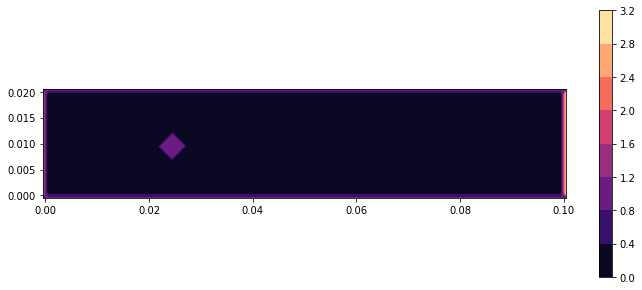

In [3]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation

fig = plt.figure(figsize = (10,4))
ax = fig.add_subplot(111)

cvals = np.linspace(0,2,4)
cont = ax.contourf(x_c, y_c, bc_Mask, cmap=plt.cm.magma)  

plt.gca().set_aspect("equal")
plt.tight_layout()

fig.colorbar(cont)

In [4]:
def CPM(x_c, y_c, x_f, y_f, U, V, p, rho, E, vorticity, M_flux_x, M_flux_y, delta_x, delta_y):
    '''
    Решение уравнений газовой динамики с использованием метода 
    крупных частиц (coarse particles method). 
    
    Параметры:
    
    '''
    
    global delta_t, rho_0, p_0, E_0
    
    
    Nx, Ny = x_c.shape 
    Nx = Nx - 2
    Ny = Ny - 2
    
#    print(Nx, Ny)
    
    # Граничные условия для p, U, V. 
    for i in range(1,Nx+1):
        for j in range(1,Ny+1):
            if (bc_Mask[i,j] == 0):
                if (bc_Mask[i-1,j] != 0):
                    if (bc_Mask[i-1,j] == 1): 
                        p[i-1,j] = p[i,j]
                        rho[i-1,j] = rho[i,j]
                        U[i-1,j] = -U[i,j]
                        V[i-1,j] = V[i,j]
                    if (bc_Mask[i-1,j] == 3):
                        p[i-1,j] = p[i,j]
                        rho[i-1,j] = rho[i,j]
                        U[i-1,j] = U[i,j]
                        V[i-1,j] = V[i,j]
                    if (bc_Mask[i-1,j] == 2):
                        U[i-1,j] = 500.0 #np.sqrt(abs((p[i,j]-p[i-1,j])*(rho[i,j]-rho[i-1,j])/rho[i,j]/rho[i-1,j]))
                        V[i-1,j] = 0.0
                        
                if (bc_Mask[i+1,j] != 0):      
                    if (bc_Mask[i+1,j] == 1): 
                        p[i+1,j] = p[i,j]
                        rho[i+1,j] = rho[i,j]
                        U[i+1,j] = -U[i,j]
                        V[i+1,j] = V[i,j]
                    if (bc_Mask[i+1,j] == 3):
                        U[i+1,j] = np.sqrt(abs((p[i,j]-p[i+1,j])*(rho[i,j]-rho[i+1,j])/rho[i,j]/rho[i+1,j])) #U[i,j]
                        V[i+1,j] = V[i,j]
                    if (bc_Mask[i+1,j] == 2):
                        U[i+1,j] = -np.sqrt(abs((p[i,j]-p[i+1,j])*(rho[i,j]-rho[i+1,j])/rho[i,j]/rho[i+1,j]))
                        V[i+1,j] = 0.0  
                        
                if (bc_Mask[i,j-1] != 0):        
                    if (bc_Mask[i,j-1] == 1): 
                        p[i,j-1] = p[i,j]
                        rho[i,j-1] = rho[i,j]
                        U[i,j-1] = U[i,j]
                        V[i,j-1] = -V[i,j]
                    if (bc_Mask[i,j-1] == 3):
                        p[i,j-1] = p[i,j]
                        rho[i,j-1] = rho[i,j]
                        U[i,j-1] = U[i,j]
                        V[i,j-1] = V[i,j]
                    if (bc_Mask[i,j-1] == 2):
                        U[i,j-1] = 0.0
                        V[i,j-1] = np.sqrt(abs((p[i,j]-p[i,j-1])*(rho[i,j]-rho[i,j-1])/rho[i,j]/rho[i,j-1]))
    
                if (bc_Mask[i,j+1] != 0):  
                    if (bc_Mask[i,j+1] == 1): 
                        p[i,j+1] = p[i,j]
                        rho[i,j+1] = rho[i,j]
                        U[i,j+1] = U[i,j]
                        V[i,j+1] = -V[i,j]
                    if (bc_Mask[i,j+1] == 3):
                        p[i,j+1] = p[i,j]
                        rho[i,j+1] = rho[i,j]
                        U[i,j+1] = U[i,j]
                        V[i,j+1] = V[i,j]
                    if (bc_Mask[i,j+1] == 2):
                        U[i,j+1] = 0.0
                        V[i,j+1] = np.sqrt(abs((p[i,j]-p[i,j+1])*(rho[i,j]-rho[i,j+1])/rho[i,j]/rho[i,j+1]))
    
    U_int = U.copy() 
    V_int = V.copy()
    E_int = E.copy()
    
    rho_old = rho.copy()    
    
    # 1. Эйлеров этап.
    for i in range(1,Nx+1):
        for j in range(1,Ny+1):
            
            if (bc_Mask[i,j] == 0):
            
     #           q_r = -0.05*(U[i+1,j]-U[i,j])/delta_x
     #           q_l = -0.05*(U[i,j]-U[i-1,j])/delta_x
                
                p_r = 0.5*(p[i,j] + p[i+1,j]) #+ q_r
                p_l = 0.5*(p[i-1,j] + p[i,j]) #+ q_l
                U_int[i,j] = U_int[i,j] - (p_r - p_l)*delta_t/rho[i,j]/delta_x

       #         q_t = -0.05*(V[i,j+1]-V[i,j])/delta_x
       #         q_b = -0.05*(V[i,j]-V[i,j-1])/delta_x
    
                p_t = 0.5*(p[i,j+1] + p[i,j]) #+ q_t
                p_b = 0.5*(p[i,j] + p[i,j-1]) #+ q_b
                V_int[i,j] = V_int[i,j] - (p_t - p_b)*delta_t/rho[i,j]/delta_y


                U_r = 0.5*(U[i,j] + U[i+1,j])
                U_l = 0.5*(U[i-1,j] + U[i,j])
                V_t = 0.5*(V[i,j+1] + V[i,j])
                V_b = 0.5*(V[i,j] + V[i,j-1])

                E_int[i,j] = E_int[i,j] - ( (p_r*U_r - p_l*U_l)/delta_x + (p_t*V_t - p_b*V_b)/delta_y)*delta_t/rho[i,j] 

    # 2. Лагранжев этап.
    
    # Гран. условия на rho, U_int, V_int. 
    for i in range(1,Nx+1):
        for j in range(1,Ny+1):
            if (bc_Mask[i,j] == 0):
                if (bc_Mask[i-1,j] != 0):
                    if (bc_Mask[i-1,j] == 1): 
                        U_int[i-1,j] = -U_int[i,j]
                        V_int[i-1,j] = V_int[i,j]
                    if (bc_Mask[i-1,j] == 3):
                        U_int[i-1,j] = U_int[i,j]
                        V_int[i-1,j] = V_int[i,j]
                    if (bc_Mask[i-1,j] == 2):
                        U_int[i-1,j] = U[i-1,j]
                        V_int[i-1,j] = 0.0
                        
                if (bc_Mask[i+1,j] != 0):      
                    if (bc_Mask[i+1,j] == 1): 
                        U_int[i+1,j] = -U_int[i,j]
                        V_int[i+1,j] = V_int[i,j]
                    if (bc_Mask[i+1,j] == 3):
                        U_int[i+1,j] = U_int[i,j]
                        V_int[i+1,j] = V_int[i,j]
                    if (bc_Mask[i+1,j] == 2):
                        U_int[i+1,j] = U[i+1,j]
                        V_int[i+1,j] = 0.0  
                        
                if (bc_Mask[i,j-1] != 0):        
                    if (bc_Mask[i,j-1] == 1): 
                        U_int[i,j-1] = U_int[i,j]
                        V_int[i,j-1] = -V_int[i,j]
                    if (bc_Mask[i,j-1] == 3):
                        U_int[i,j-1] = U_int[i,j]
                        V_int[i,j-1] = V_int[i,j]
                    if (bc_Mask[i,j-1] == 2):
                        U_int[i,j-1] = 0.0
                        V_int[i,j-1] = V[i,j-1]
                        
                if (bc_Mask[i,j+1] != 0):  
                    if (bc_Mask[i,j+1] == 1): 
                        U_int[i,j+1] = U_int[i,j]
                        V_int[i,j+1] = -V_int[i,j]
                    if (bc_Mask[i,j+1] == 3):
                        U_int[i,j+1] = U_int[i,j]
                        V_int[i,j+1] = V_int[i,j]
                    if (bc_Mask[i,j+1] == 2):
                        U_int[i,j+1] = 0.0
                        V_int[i,j+1] = V[i,j+1]
    
    # Поток массы по оси x
    for i in range(1,Nx+2):
        for j in range(1,Ny+1):
            av_velo_x = (U_int[i-1,j] + U_int[i,j])/2 
            if(av_velo_x > 0):
                M_flux_x[i,j] = rho[i-1,j]*av_velo_x*delta_y*delta_t
            else:
                M_flux_x[i,j] = rho[i,j]*av_velo_x*delta_y*delta_t

    for i in range(1,Nx+1):
        for j in range(1,Ny+2):
            av_velo_y = (V_int[i,j-1] + V_int[i,j])/2 
            if(av_velo_y > 0):
                M_flux_y[i,j] = rho[i,j-1]*av_velo_y*delta_y*delta_t
            else:
                M_flux_y[i,j] = rho[i,j]*av_velo_y*delta_y*delta_t
                
            
    # 3. Заключительный этап

    for i in range(1,Nx+1):
        for j in range(1,Ny+1):
            rho[i,j] = rho[i,j] + (M_flux_x[i,j] - M_flux_x[i+1,j] + M_flux_y[i,j] - M_flux_y[i,j+1])/delta_x/delta_y     
        
    # Гран. условия для E_int    
# Граничные условия для p, U, V. 
    for i in range(1,Nx+1):
        for j in range(1,Ny+1):
            if (bc_Mask[i,j] == 0):
                if (bc_Mask[i-1,j] != 0):
                    if (bc_Mask[i-1,j] != 3):
                        E_int[i-1,j] = E_int[i,j]
                    else:
                        E_int[i-1,j] = E[i-1,j]
                if (bc_Mask[i+1,j] != 0):
                    if (bc_Mask[i+1,j] == 1):
                        E_int[i+1,j] = E_int[i,j]
                    if (bc_Mask[i+1,j] == 2):
                        E_int[i+1,j] = E[i+1,j]
                    if (bc_Mask[i+1,j] == 3):
                        E_int[i+1,j] = E[i+1,j]
                if (bc_Mask[i,j-1] != 0):
                    if (bc_Mask[i,j-1] != 3):
                        E_int[i,j-1] = E_int[i,j]
                    else:
                        E_int[i,j-1] = E[i,j-1]
                if (bc_Mask[i,j+1] != 0):
                    if (bc_Mask[i,j+1] != 3):
                        E_int[i,j+1] = E_int[i,j]
                    else:
                        E_int[i,j+1] = E[i,j+1]
                    
                    
    
    for i in range(1,Nx+1):
        for j in range(1,Ny+1):
            
            av_velo_x_l = U_int[i,j] + U_int[i-1,j]
            av_velo_x_r = U_int[i+1,j] + U_int[i,j]
            av_velo_y_b = V_int[i,j] + V_int[i,j-1]
            av_velo_y_t = V_int[i,j+1] + V_int[i,j]
            
            D11 = 0
            D12 = 0
            D21 = 0
            D22 = 0
            
            if(av_velo_x_l > 0):
                D11 = 1
 
            if(av_velo_x_r < 0):
                D12 = 1

            if(av_velo_y_b > 0):
                D21 = 1

            if(av_velo_y_t < 0):
                D22 = 1
                            
            U[i,j] = (D11*abs(M_flux_x[i,j])*U_int[i-1,j] + D12*abs(M_flux_x[i+1,j])*U_int[i+1,j] + D21*abs(M_flux_y[i,j])*U_int[i,j-1] + D22*abs(M_flux_y[i,j+1])*U_int[i,j+1] + \
                      U_int[i,j]*(delta_x*delta_y*rho_old[i,j] - (1-D11)*abs(M_flux_x[i,j]) - (1-D12)*abs(M_flux_x[i+1,j]) - (1-D21)*abs(M_flux_y[i,j]) - (1-D22)*abs(M_flux_y[i,j+1])))/delta_x/delta_y/rho[i,j]
 
            V[i,j] = (D11*abs(M_flux_x[i,j])*V_int[i-1,j] + D12*abs(M_flux_x[i+1,j])*V_int[i+1,j] + D21*abs(M_flux_y[i,j])*V_int[i,j-1] + D22*abs(M_flux_y[i,j+1])*V_int[i,j+1] + \
                      V_int[i,j]*(delta_x*delta_y*rho_old[i,j] - (1-D11)*abs(M_flux_x[i,j]) - (1-D12)*abs(M_flux_x[i+1,j]) - (1-D21)*abs(M_flux_y[i,j]) - (1-D22)*abs(M_flux_y[i,j+1])))/delta_x/delta_y/rho[i,j]
            
            E[i,j] = (D11*abs(M_flux_x[i,j])*E_int[i-1,j] + D12*abs(M_flux_x[i+1,j])*E_int[i+1,j] + D21*abs(M_flux_y[i,j])*E_int[i,j-1] + D22*abs(M_flux_y[i,j+1])*E_int[i,j+1] + \
                      E_int[i,j]*(delta_x*delta_y*rho_old[i,j] - (1-D11)*abs(M_flux_x[i,j]) - (1-D12)*abs(M_flux_x[i+1,j]) - (1-D21)*abs(M_flux_y[i,j]) - (1-D22)*abs(M_flux_y[i,j+1])))/delta_x/delta_y/rho[i,j]
            
            
# 4. Уравнение состояния

    for i in range(1,Nx+1):
        for j in range(1,Ny+1):
            
            e[i,j] = E[i,j] - (U[i,j]**2 + V[i,j]**2)/2
            
            p[i,j] = e[i,j]*rho[i,j]*(gamma - 1)
            T[i,j] = p[i,j]/rho[i,j]/R*Mol_mass
            
            v_s[i,j] = np.sqrt(gamma * p[i,j] / rho[i,j])
            
            delta_t1 = CFL * delta_x / (v_s[i,j] + np.sqrt(U[i,j]**2 + V[i,j]**2))
     
            vorticity[i,j] = (U[i,j+1] - U[i,j-1])/delta_y - (V[i+1,j] - V[i-1,j])/delta_x
    
            if (delta_t1 < delta_t):
#                print(delta_t)    
                delta_t = delta_t1 
#                print (delta_t1,delta_t)
  
#    print(delta_t)
#    print(M_flux_y)


In [5]:
CPM(x_c,y_c,x_f,y_f,U,V,p,rho,E,vorticity,M_flux_x, M_flux_y,delta_x,delta_y)
print(delta_t)

1.3014681733927501e-06


In [12]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from mpl_toolkits.axes_grid1 import make_axes_locatable

from IPython.display import HTML

plt.rc('animation', html='jshtml')

fig = plt.figure(figsize=(15,5))
ax = fig.add_subplot(111)
#ax = plt.axes(xlim=(0, Lx), ylim=(0, 20), xlabel='x', ylabel='y')

plt.gca().set_aspect("equal")
plt.tight_layout()

div = make_axes_locatable(ax)
cax = div.append_axes('right', '5%', '5%')

#cb = fig.colorbar(cf, cax=cax)

cvals = np.linspace(-100,100,50)

time = 0.0

#line, = ax.plot([], [], lw=2)

def some_data(i):   # function returns a 2D data array
    
    CPM(x_c,y_c,x_f,y_f,U,V,p,rho,E,vorticity,M_flux_x, M_flux_y,delta_x,delta_y)
    
    Nx = len(x_c)
    Ny = len(y_c)
    return T #[1:Nx+1,1:Ny+1]

def init():
    z = some_data(0)
    cvals = np.linspace(np.amin(z),np.amax(z),100)

    cont = ax.contourf(x_c, y_c, z, cvals, cmap=plt.cm.jet)    # first image on screen
    cax.cla()
    fig.colorbar(cont, cax=cax)

#    line.set_data([],[])
    return(cont)

# animation function
def animate(i):
    global time
    time = time + delta_t
    i = i + 1
    z = some_data(i)

    cvals = np.linspace(np.amin(z),np.amax(z),100)
    cont = ax.contourf(x_c, y_c, z, cvals, cmap=plt.cm.jet)

#    line.set_data(x_c[:,1], z[:,1])
    ax.set_title('t = %.5e' % (i*delta_t))
    print ('Iteration %2i; Calculation time, %.5e; Time step = %.5e' % (i,time,delta_t))
    cax.cla()
    fig.colorbar(cont, cax=cax)
#    quiv = ax.quiver(x_c, y_c, U, V, color='Black', headlength=7)
    return (cont)

anim = animation.FuncAnimation(fig, animate, init_func = init, frames=500, repeat=False)
plt.close() 
anim


Iteration  1; Calculation time, 1.16745e-06; Time step = 1.11478e-06
Iteration  2; Calculation time, 2.28224e-06; Time step = 1.09724e-06
Iteration  3; Calculation time, 3.37947e-06; Time step = 1.09724e-06
Iteration  4; Calculation time, 4.47671e-06; Time step = 1.09724e-06
Iteration  5; Calculation time, 5.57394e-06; Time step = 1.09724e-06
Iteration  6; Calculation time, 6.67118e-06; Time step = 1.09724e-06
Iteration  7; Calculation time, 7.76842e-06; Time step = 1.09724e-06
Iteration  8; Calculation time, 8.86565e-06; Time step = 1.09724e-06
Iteration  9; Calculation time, 9.96289e-06; Time step = 1.09724e-06
Iteration 10; Calculation time, 1.10601e-05; Time step = 1.09364e-06
Iteration 11; Calculation time, 1.21538e-05; Time step = 1.08870e-06
Iteration 12; Calculation time, 1.32425e-05; Time step = 1.08436e-06
Iteration 13; Calculation time, 1.43268e-05; Time step = 1.08035e-06
Iteration 14; Calculation time, 1.54072e-05; Time step = 1.07644e-06
Iteration 15; Calculation time, 1.

Iteration 120; Calculation time, 1.22163e-04; Time step = 9.84769e-07
Iteration 121; Calculation time, 1.23147e-04; Time step = 9.84755e-07
Iteration 122; Calculation time, 1.24132e-04; Time step = 9.84741e-07
Iteration 123; Calculation time, 1.25117e-04; Time step = 9.84729e-07
Iteration 124; Calculation time, 1.26102e-04; Time step = 9.84717e-07
Iteration 125; Calculation time, 1.27086e-04; Time step = 9.84706e-07
Iteration 126; Calculation time, 1.28071e-04; Time step = 9.84696e-07
Iteration 127; Calculation time, 1.29056e-04; Time step = 9.84687e-07
Iteration 128; Calculation time, 1.30040e-04; Time step = 9.84678e-07
Iteration 129; Calculation time, 1.31025e-04; Time step = 9.84670e-07
Iteration 130; Calculation time, 1.32010e-04; Time step = 9.84663e-07
Iteration 131; Calculation time, 1.32994e-04; Time step = 9.84656e-07
Iteration 132; Calculation time, 1.33979e-04; Time step = 9.84649e-07
Iteration 133; Calculation time, 1.34964e-04; Time step = 9.84643e-07
Iteration 134; Calcu

Iteration 238; Calculation time, 2.38344e-04; Time step = 9.84564e-07
Iteration 239; Calculation time, 2.39329e-04; Time step = 9.84564e-07
Iteration 240; Calculation time, 2.40313e-04; Time step = 9.84564e-07
Iteration 241; Calculation time, 2.41298e-04; Time step = 9.84564e-07
Iteration 242; Calculation time, 2.42282e-04; Time step = 9.84564e-07
Iteration 243; Calculation time, 2.43267e-04; Time step = 9.84564e-07
Iteration 244; Calculation time, 2.44251e-04; Time step = 9.84564e-07
Iteration 245; Calculation time, 2.45236e-04; Time step = 9.84564e-07
Iteration 246; Calculation time, 2.46221e-04; Time step = 9.84564e-07
Iteration 247; Calculation time, 2.47205e-04; Time step = 9.84564e-07
Iteration 248; Calculation time, 2.48190e-04; Time step = 9.84564e-07
Iteration 249; Calculation time, 2.49174e-04; Time step = 9.84564e-07
Iteration 250; Calculation time, 2.50159e-04; Time step = 9.84564e-07
Iteration 251; Calculation time, 2.51143e-04; Time step = 9.84564e-07
Iteration 252; Calcu

Iteration 356; Calculation time, 3.54523e-04; Time step = 9.84564e-07
Iteration 357; Calculation time, 3.55507e-04; Time step = 9.84564e-07
Iteration 358; Calculation time, 3.56492e-04; Time step = 9.84564e-07
Iteration 359; Calculation time, 3.57476e-04; Time step = 9.84564e-07
Iteration 360; Calculation time, 3.58461e-04; Time step = 9.84564e-07
Iteration 361; Calculation time, 3.59445e-04; Time step = 9.84564e-07
Iteration 362; Calculation time, 3.60430e-04; Time step = 9.84564e-07
Iteration 363; Calculation time, 3.61415e-04; Time step = 9.84564e-07
Iteration 364; Calculation time, 3.62399e-04; Time step = 9.84564e-07
Iteration 365; Calculation time, 3.63384e-04; Time step = 9.84564e-07
Iteration 366; Calculation time, 3.64368e-04; Time step = 9.84564e-07
Iteration 367; Calculation time, 3.65353e-04; Time step = 9.84564e-07
Iteration 368; Calculation time, 3.66337e-04; Time step = 9.84564e-07
Iteration 369; Calculation time, 3.67322e-04; Time step = 9.84564e-07
Iteration 370; Calcu

Iteration 474; Calculation time, 4.70701e-04; Time step = 9.84564e-07
Iteration 475; Calculation time, 4.71686e-04; Time step = 9.84564e-07
Iteration 476; Calculation time, 4.72670e-04; Time step = 9.84564e-07
Iteration 477; Calculation time, 4.73655e-04; Time step = 9.84564e-07
Iteration 478; Calculation time, 4.74639e-04; Time step = 9.84564e-07
Iteration 479; Calculation time, 4.75624e-04; Time step = 9.84564e-07
Iteration 480; Calculation time, 4.76609e-04; Time step = 9.84564e-07
Iteration 481; Calculation time, 4.77593e-04; Time step = 9.84564e-07
Iteration 482; Calculation time, 4.78578e-04; Time step = 9.84564e-07
Iteration 483; Calculation time, 4.79562e-04; Time step = 9.84564e-07
Iteration 484; Calculation time, 4.80547e-04; Time step = 9.84564e-07
Iteration 485; Calculation time, 4.81531e-04; Time step = 9.84564e-07
Iteration 486; Calculation time, 4.82516e-04; Time step = 9.84564e-07
Iteration 487; Calculation time, 4.83500e-04; Time step = 9.84564e-07
Iteration 488; Calcu

---

#### Задача 13
> Введите в процедуре `CABARET` настроечный параметр $\alpha$ регулирующий ширину области допустимых пределов изменения потоковой величины на этапе коррекции. Сопоставьте решения получаемые с использованием различных значений $\alpha$.

---

## Список литературы.

1. "Новые алгоритмы вычислительной гидродинамики для многопроцессорных вычислитлельных комплексов" *В.М. Головизнин, М.А. Зайцев, С.А. Карабасов, И.А. Короткин* ([МГУ ВМК](http://lim.cs.msu.ru/index.php?id=87), 2013)
2. "Дисперсионные и диссипативные характеристики разностных схем для уравнений в частных производных гиперболического типа" *В.М. Головизнин, А.В. Соловьев* ([МГУ ВМК](http://lim.cmc.msu.ru/index.php?id=9), 2018)
3. "Burgers equation" *Mikel Landjuela* BCAM Internship ([Basque center for applied mathematics(pdf)](http://www.bcamath.org/projects/NUMERIWAVES/Burgers_Equation_M_Landajuela.pdf), 2011)
4. "Numerical Methods for Conservation Laws" *Randall J. LeVeque* ([Springer](https://www.springer.com/gp/book/9783764327231), 1992)
5. "Riemann Solvers and Numerical Methods for Fluid Dynamics" *Eleuterio Toro* ([Springer](https://www.springer.com/gp/book/9783540252023), 2009)



---
**Ячейка снизу загружает стилевую конфигурацию блокнота.**

In [7]:
from IPython.core.display import HTML
def css_styling():
    styles = open("./custom.css", "r").read()
    return HTML(styles)
css_styling()